In [1]:
import numpy as np
from NN import LNN_trjectory

np.random.seed(42)
h=20
layers = h

model = LNN_trjectory(layers =h)
model.read_data("spring_data_no_control.csv")
model.W1  = 0.1 * np.random.randn(layers, 2)
model.b1  = np.zeros(layers)
model.WN  = 0.1 * np.abs(np.random.randn(1, layers))
model.bN  = -5.0 * np.ones(1)
model.epsilon = 0.1

model.forward_pass()
#print(model.X[:,0,1])
print(model.loss())
learning_rate = 1e-2
Episodes = 1000
for epoch in range(Episodes):
    model.train_step(learning_rate)
    if epoch % int(Episodes/10) == 0:
        print(f"Epoch {epoch:4d}  Loss = {model.loss():.6f}")
        learning_rate = learning_rate * 0.9
print(f"Epoch {epoch:4d}  Loss = {model.loss():.6f}")

226.7839966994557
Epoch    0  Loss = 226.783997
Epoch  100  Loss = 11.918302
Epoch  200  Loss = 7.340391
Epoch  300  Loss = 0.364473
Epoch  400  Loss = 0.014704
Epoch  500  Loss = 0.014599
Epoch  600  Loss = 0.014507
Epoch  700  Loss = 0.014425
Epoch  800  Loss = 0.014352
Epoch  900  Loss = 0.014287
Epoch  999  Loss = 0.014230


In [2]:
import numpy as np
from NN import LNN_structured

np.random.seed(42)
h=20
layers = h
model_structured = LNN_structured(layers =h)
model_structured.read_data("spring_data_no_control.csv")
model_structured.W1z = 0.1 * np.random.randn(layers, 1) 
model_structured.W1v = np.random.randn(layers, 1)
model_structured.b1z = np.zeros(layers)
model_structured.b1v = np.zeros(layers)
model_structured.WNz = 0.01 * np.random.randn(1, layers)
model_structured.WNv = np.abs(np.random.randn(1, layers)) / np.sqrt(layers)
model_structured.bNz = np.array([np.log(2.0)])
model_structured.bNv = np.zeros(1)

# --- Diagnose VOR dem Training ---
model_structured.forward_pass()
print(f"M[0] mean = {model_structured.M_hist[0].mean():.3f}")     # Ziel: ~2
print(f"Vq[0] mean = {model_structured.Vq[0].mean():.3f}")        # Ziel: ~0.5·q
print(f"X range   = [{model_structured.X[:,0,:].min():.2f}, {model_structured.X[:,0,:].max():.2f}]")
print(f"Q_data    = [{model_structured.Q_data.min():.2f}, {model_structured.Q_data.max():.2f}]")

# --- Training ---
learning_rate = 1e-2
Episodes = 1000
for epoch in range(Episodes):
    model_structured.train_step(learning_rate)
    if epoch % 200 == 0:
        print(f"Epoch {epoch:4d}  Loss = {model_structured.loss():.6f}")
print(f"Epoch {epoch:4d}  Loss = {model_structured.loss():.6f}")

M[0] mean = 1.301
Vq[0] mean = 0.345
X range   = [-6.04, 2.13]
Q_data    = [-3.19, 3.19]
Epoch    0  Loss = 3.733811
Epoch  200  Loss = 0.251766
Epoch  400  Loss = 0.152265
Epoch  600  Loss = 0.062814
Epoch  800  Loss = 0.027349
Epoch  999  Loss = 0.022504


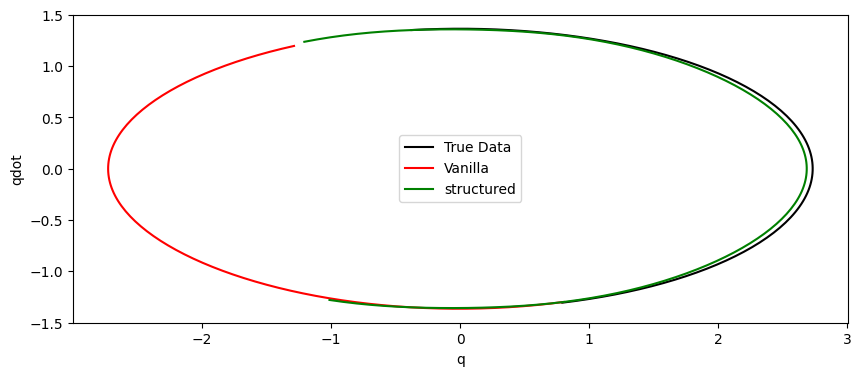

H min/max/mean: 0.100 / 0.100 / 0.100


In [3]:
# Vergleich vom Vanilla zur strukturierten Ansatz 
import matplotlib.pyplot as plt
model.forward_pass()
model_structured.forward_pass()
plt.figure(figsize=(10,4))

plt.plot(
    model.Q_data[0:150,0], 
    model.Qdot_data[0:150,0], 
    'k-',
    label = 'True Data')

plt.plot(
    model.X[150:300,0,0], 
    model.X[150:300,1,0], 
    'r-', 
    label = 'Vanilla')

plt.plot(
    model_structured.X[300:500,0,0], 
    model_structured.X[300:500,1,0], 
    'g-', 
    label = 'structured')

plt.legend()
plt.xlabel('q'); plt.ylabel('qdot'); #plt.title('LNN')
plt.show()
print(f"H min/max/mean: {model.H.min():.3f} / {model.H.max():.3f} / {model.H.mean():.3f}")

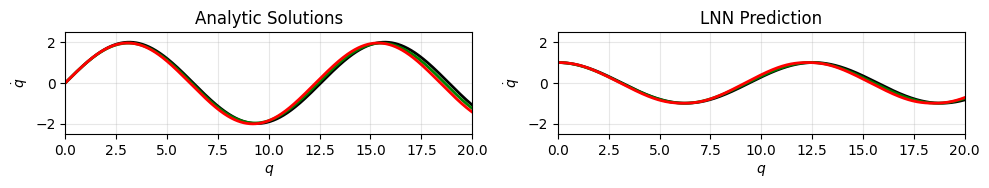

q_l   range: -1.972600522992082 1.9546520371034406
qd_l  range: -1.0002122346924354 1.0001453765202608


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Meine speziellen Parameter: w = k/m
omega = 0.5

def qddot_learned(q, qdot, u=0):
    dLdq, _, C, H = model.forward(q, qdot)
    return (dLdq[0] - C[0]*qdot + u) / H[0]

def qddot_structured(q, qdot, u=0):
    M, Mq, Vq = model_structured.forward(q,qdot)
    return (1/M)*(-1/2 * Mq*qdot**2 - Vq + u)

def rk4_step(q, qdot, u, h, method='vanilla'):
    if method == 'vanilla':
        k1_q, k1_qd = qdot, qddot_learned(q, qdot, u)
        k2_q, k2_qd = qdot+h/2*k1_qd, qddot_learned(q+h/2*k1_q, qdot+h/2*k1_qd, u)
        k3_q, k3_qd = qdot+h/2*k2_qd, qddot_learned(q+h/2*k2_q, qdot+h/2*k2_qd, u)
        k4_q, k4_qd = qdot+h*k3_qd,   qddot_learned(q+h*k3_q,   qdot+h*k3_qd,   u)
        return q+h/6*(k1_q+2*k2_q+2*k3_q+k4_q), qdot+h/6*(k1_qd+2*k2_qd+2*k3_qd+k4_qd)
    if method == 'structured':
        k1_q, k1_qd = qdot, qddot_structured(q, qdot, u)
        k2_q, k2_qd = qdot+h/2*k1_qd, qddot_structured(q+h/2*k1_q, qdot+h/2*k1_qd, u)
        k3_q, k3_qd = qdot+h/2*k2_qd, qddot_structured(q+h/2*k2_q, qdot+h/2*k2_qd, u)
        k4_q, k4_qd = qdot+h*k3_qd,   qddot_structured(q+h*k3_q,   qdot+h*k3_qd,   u)
        return q+h/6*(k1_q+2*k2_q+2*k3_q+k4_q), qdot+h/6*(k1_qd+2*k2_qd+2*k3_qd+k4_qd)


h = 0.01
T_end = 20.0
t_grid = np.arange(0, T_end + h, h)

q0, qdot0 = 0.0, 1.0

q_l = np.zeros(len(t_grid)); q_structured = np.zeros(len(t_grid))
qd_l = np.zeros(len(t_grid)); qd_structured = np.zeros(len(t_grid))
q_l[0], qd_l[0] = q0, qdot0
q_structured[0], qd_structured[0] = q0, qdot0

# Precition mittels Vanilla Ansatz
for i in range(len(t_grid)-1):
    q_l[i+1], qd_l[i+1] = rk4_step(
        q_l[i], qd_l[i], 0.0, h, 'vanilla')

# Prediction mittels strukturiertem Ansatz
for i in range(len(t_grid)-1):
    q_structured[i+1], qd_structured[i+1] = rk4_step(
        q_structured[i], qd_structured[i], 0.0, h, 'structured')

# Analytische Vergleichslösung
q_true  = q0*np.cos(omega*t_grid) + (qdot0/omega)*np.sin(omega*t_grid)
qd_true = -q0*omega*np.sin(omega*t_grid) + qdot0*np.cos(omega*t_grid)

fig, ax = plt.subplots(1, 2, figsize=(10, 6))

# Position: 
ax[0].plot(t_grid, q_true, 'k-', linewidth=2, label='Analytisch')
ax[0].plot(t_grid,q_l , 'g-', linewidth=2, label='Analytisch')
ax[0].plot(t_grid,q_structured , 'r-', linewidth=2, label='Analytisch')
ax[0].set_xlabel('$q$')
ax[0].set_ylabel('$\\dot q$')
ax[0].set_title('Analytic Solutions')
ax[0].grid(alpha=0.3)
ax[0].set_aspect('equal')

# Geschwindigkeit:
ax[1].plot(t_grid , qd_true , 'k-', linewidth=2, label='LNN')
ax[1].plot(t_grid ,qd_l, 'g-', linewidth=2, label='LNN')
ax[1].plot(t_grid ,qd_structured, 'r-', linewidth=2, label='LNN')
ax[1].set_xlabel('$q$')
ax[1].set_ylabel('$\\dot q$')
ax[1].set_title('LNN Prediction')
ax[1].grid(alpha=0.3)
ax[1].set_aspect('equal')

# Gemeinsame Grenzen für beide
xlim = (0.0, 20.0)
ylim = (-2.5, 2.5)
ax[0].set_xlim(xlim); ax[0].set_ylim(ylim)
ax[1].set_xlim(xlim); ax[1].set_ylim(ylim)

plt.tight_layout()

plt.show()

print("q_l   range:", q_l.min(), q_l.max())
print("qd_l  range:", qd_l.min(), qd_l.max())